# Creating and Backtesting EMA Strategies

## Getting the Data

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8")
%config InlineBackend.figure_format = "retina"

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
data = pd.read_csv("eurusd.csv", parse_dates = ["Date"], index_col = "Date")

In [4]:
data

,price
Date,
2004-01-01,1.258194
2004-01-02,1.258194
2004-01-05,1.268698
2004-01-06,1.272103
2004-01-07,1.264095
...,...
2020-06-24,1.131235
2020-06-25,1.125087
2020-06-26,1.122208


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4275 entries, 2004-01-01 to 2020-06-30
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   price   4275 non-null   float64
dtypes: float64(1)
memory usage: 66.8 KB


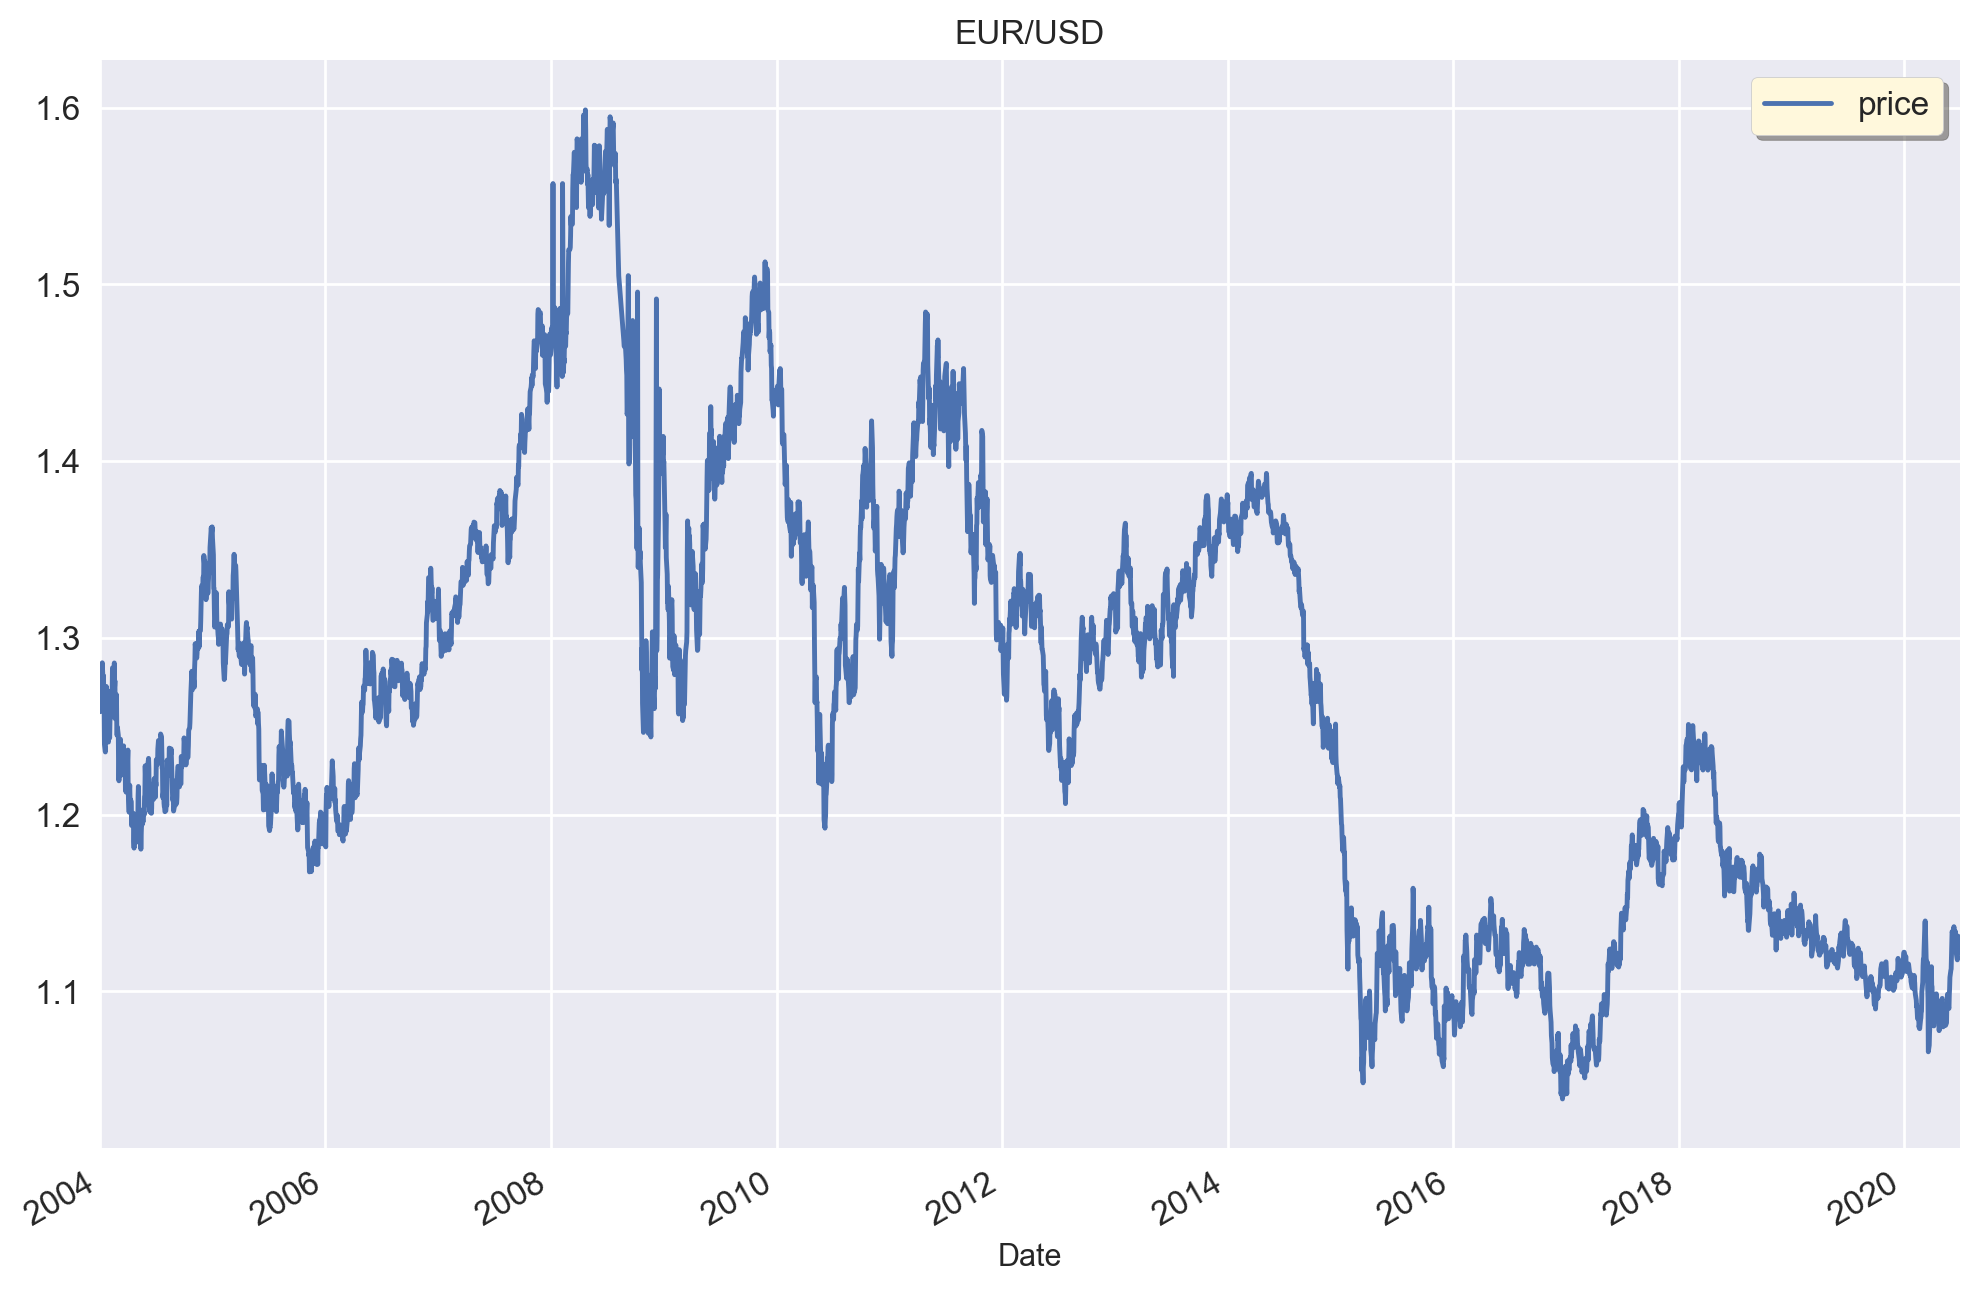

In [9]:
data.plot(figsize = (12, 8), title = "EUR/USD", fontsize = 12).autoscale(enable = True , axis = "x" , tight = True)
plt.legend(fontsize = 12 , bbox_to_anchor = (1,1) , fancybox = True , frameon = True, shadow = True , facecolor = "cornsilk")
plt.show()

## EMA vs. SMA

In [10]:
data

,price
Date,
2004-01-01,1.258194
2004-01-02,1.258194
2004-01-05,1.268698
2004-01-06,1.272103
2004-01-07,1.264095
...,...
2020-06-24,1.131235
2020-06-25,1.125087
2020-06-26,1.122208


In [11]:
window = 50

In [12]:
data.price.ewm(span= window).mean()

Date
2004-01-01    1.258194
2004-01-02    1.258194
2004-01-05    1.261836
2004-01-06    1.264559
2004-01-07    1.264458
                ...   
2020-06-24    1.109674
2020-06-25    1.110279
2020-06-26    1.110746
2020-06-29    1.111211
2020-06-30    1.111741
Name: price, Length: 4275, dtype: float64

In [13]:
data.price.ewm(span = window, min_periods = 3).mean()

Date
2004-01-01         NaN
2004-01-02         NaN
2004-01-05    1.261836
2004-01-06    1.264559
2004-01-07    1.264458
                ...   
2020-06-24    1.109674
2020-06-25    1.110279
2020-06-26    1.110746
2020-06-29    1.111211
2020-06-30    1.111741
Name: price, Length: 4275, dtype: float64

In [14]:
data.price.ewm(span = window, min_periods = window).mean()

Date
2004-01-01         NaN
2004-01-02         NaN
2004-01-05         NaN
2004-01-06         NaN
2004-01-07         NaN
                ...   
2020-06-24    1.109674
2020-06-25    1.110279
2020-06-26    1.110746
2020-06-29    1.111211
2020-06-30    1.111741
Name: price, Length: 4275, dtype: float64

In [15]:
data["EMA_S"] = data.price.ewm(span = window, min_periods = window).mean() 

In [16]:
data["SMA_S"] = data.price.rolling(window).mean() 

In [17]:
data

,price,EMA_S,SMA_S
Date,,,
2004-01-01,1.258194,NaN,NaN
2004-01-02,1.258194,NaN,NaN
2004-01-05,1.268698,NaN,NaN
2004-01-06,1.272103,NaN,NaN
2004-01-07,1.264095,NaN,NaN
...,...,...,...
2020-06-24,1.131235,1.109674,1.101794
2020-06-25,1.125087,1.110279,1.102486
2020-06-26,1.122208,1.110746,1.103213


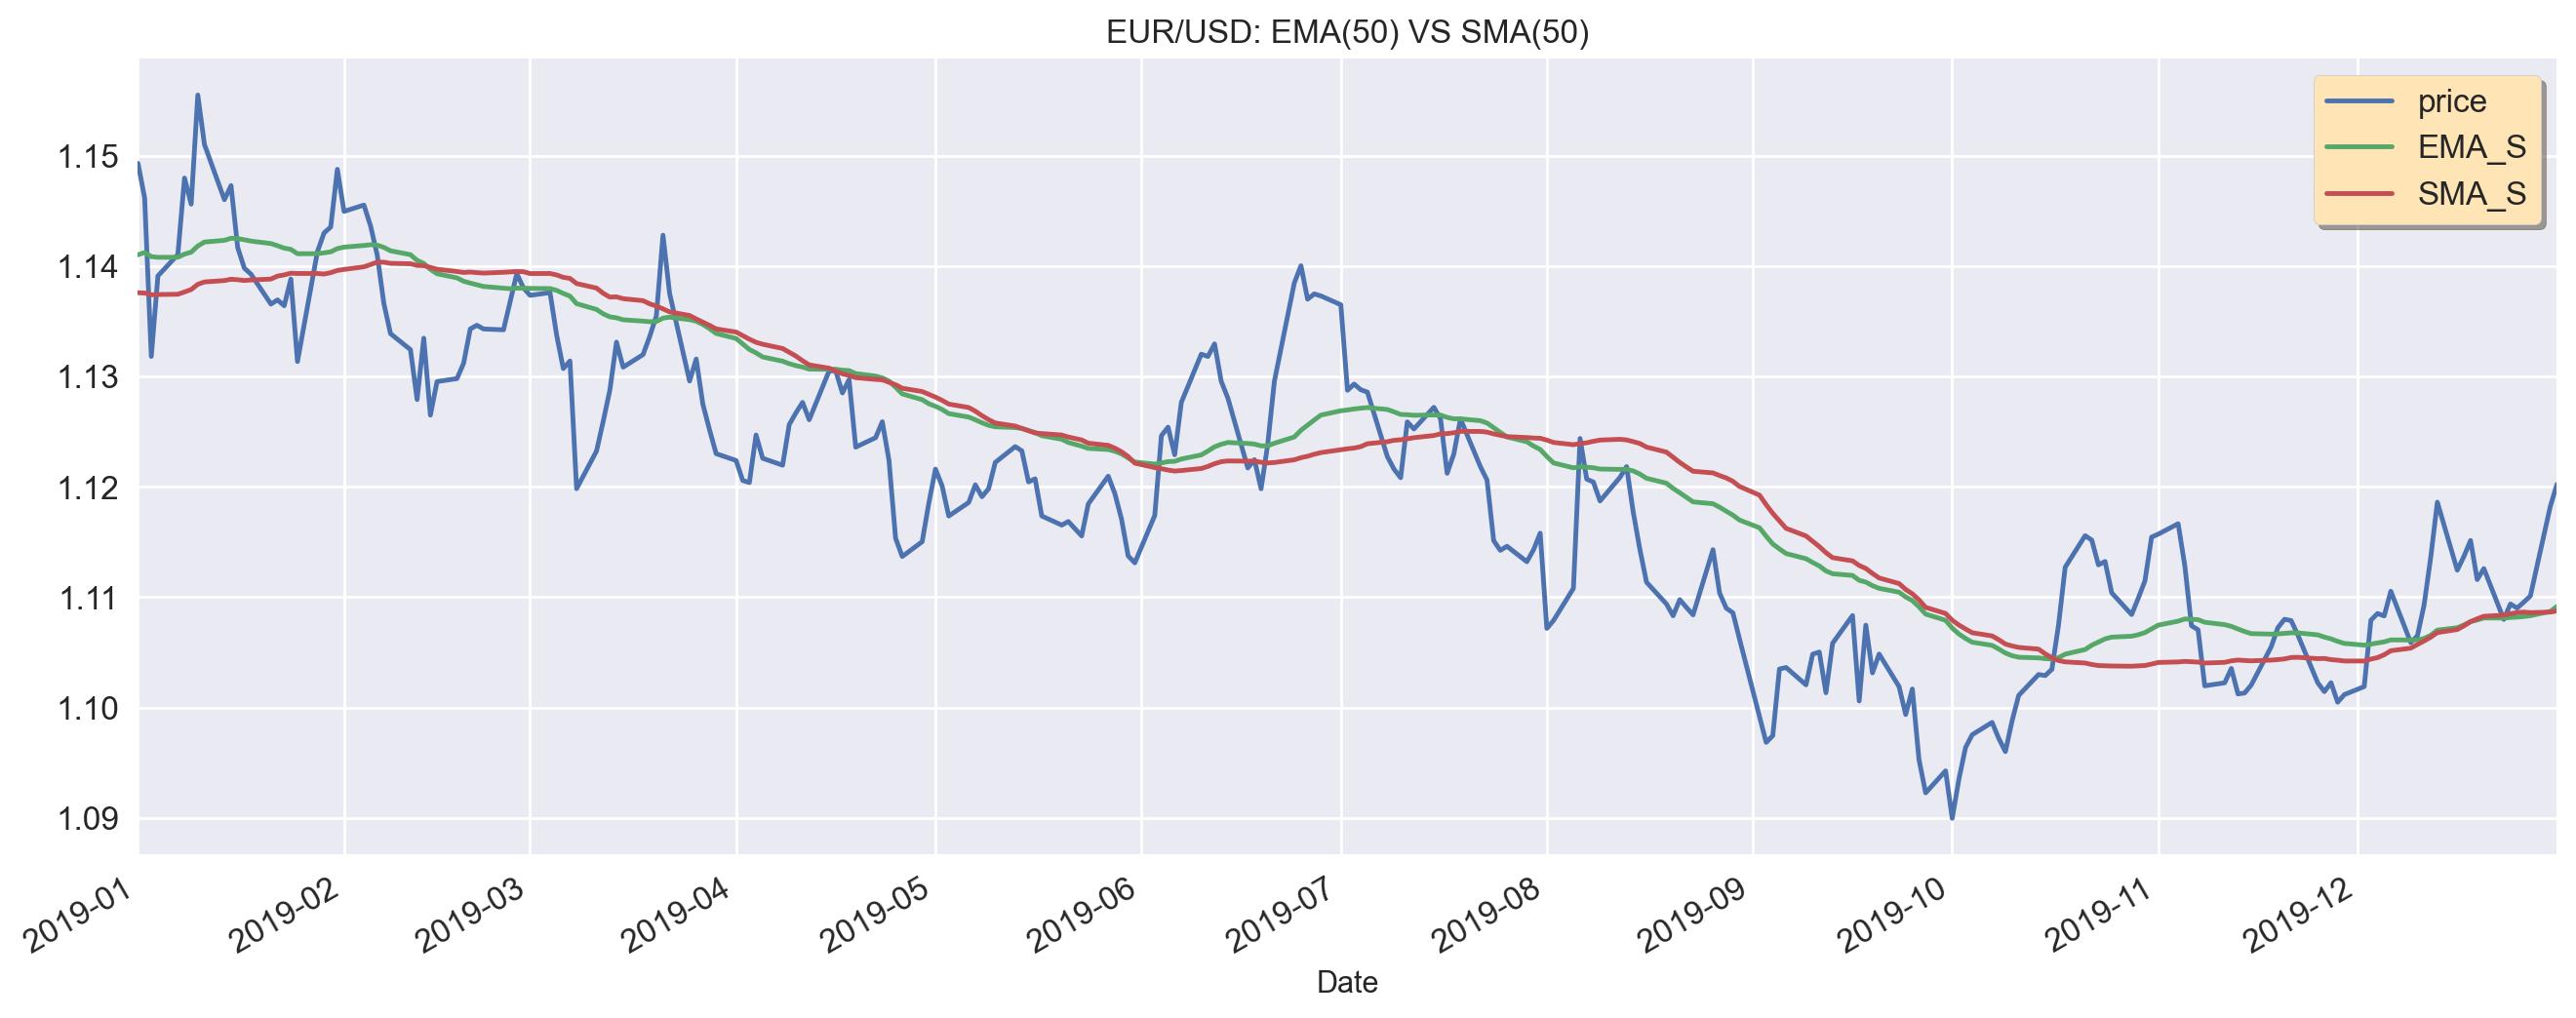

In [18]:
data.loc["2019"].plot(figsize = (16, 6), fontsize = 12).autoscale(enable = True , axis = "x" , tight = True) 
plt.title("EUR/USD: EMA(50) VS SMA(50)")
plt.legend(fontsize = 12 , bbox_to_anchor =(1,1) , fancybox = True , frameon = True, shadow = True , facecolor = "moccasin")
plt.show()

## Defining an EMA Crossover Strategy

In [19]:
data.drop(columns = ["EMA_S", "SMA_S"], inplace = True)

In [20]:
data

,price
Date,
2004-01-01,1.258194
2004-01-02,1.258194
2004-01-05,1.268698
2004-01-06,1.272103
2004-01-07,1.264095
...,...
2020-06-24,1.131235
2020-06-25,1.125087
2020-06-26,1.122208


In [21]:
ema_s = 50
ema_l = 200

In [22]:
data["EMA_S"] = data.price.ewm(span = ema_s , min_periods=ema_s).mean()
data["EMA_L"] = data.price.ewm(span = ema_l , min_periods=ema_l).mean()

In [23]:
data

,price,EMA_S,EMA_L
Date,,,
2004-01-01,1.258194,NaN,NaN
2004-01-02,1.258194,NaN,NaN
2004-01-05,1.268698,NaN,NaN
2004-01-06,1.272103,NaN,NaN
2004-01-07,1.264095,NaN,NaN
...,...,...,...
2020-06-24,1.131235,1.109674,1.106470
2020-06-25,1.125087,1.110279,1.106655
2020-06-26,1.122208,1.110746,1.106810


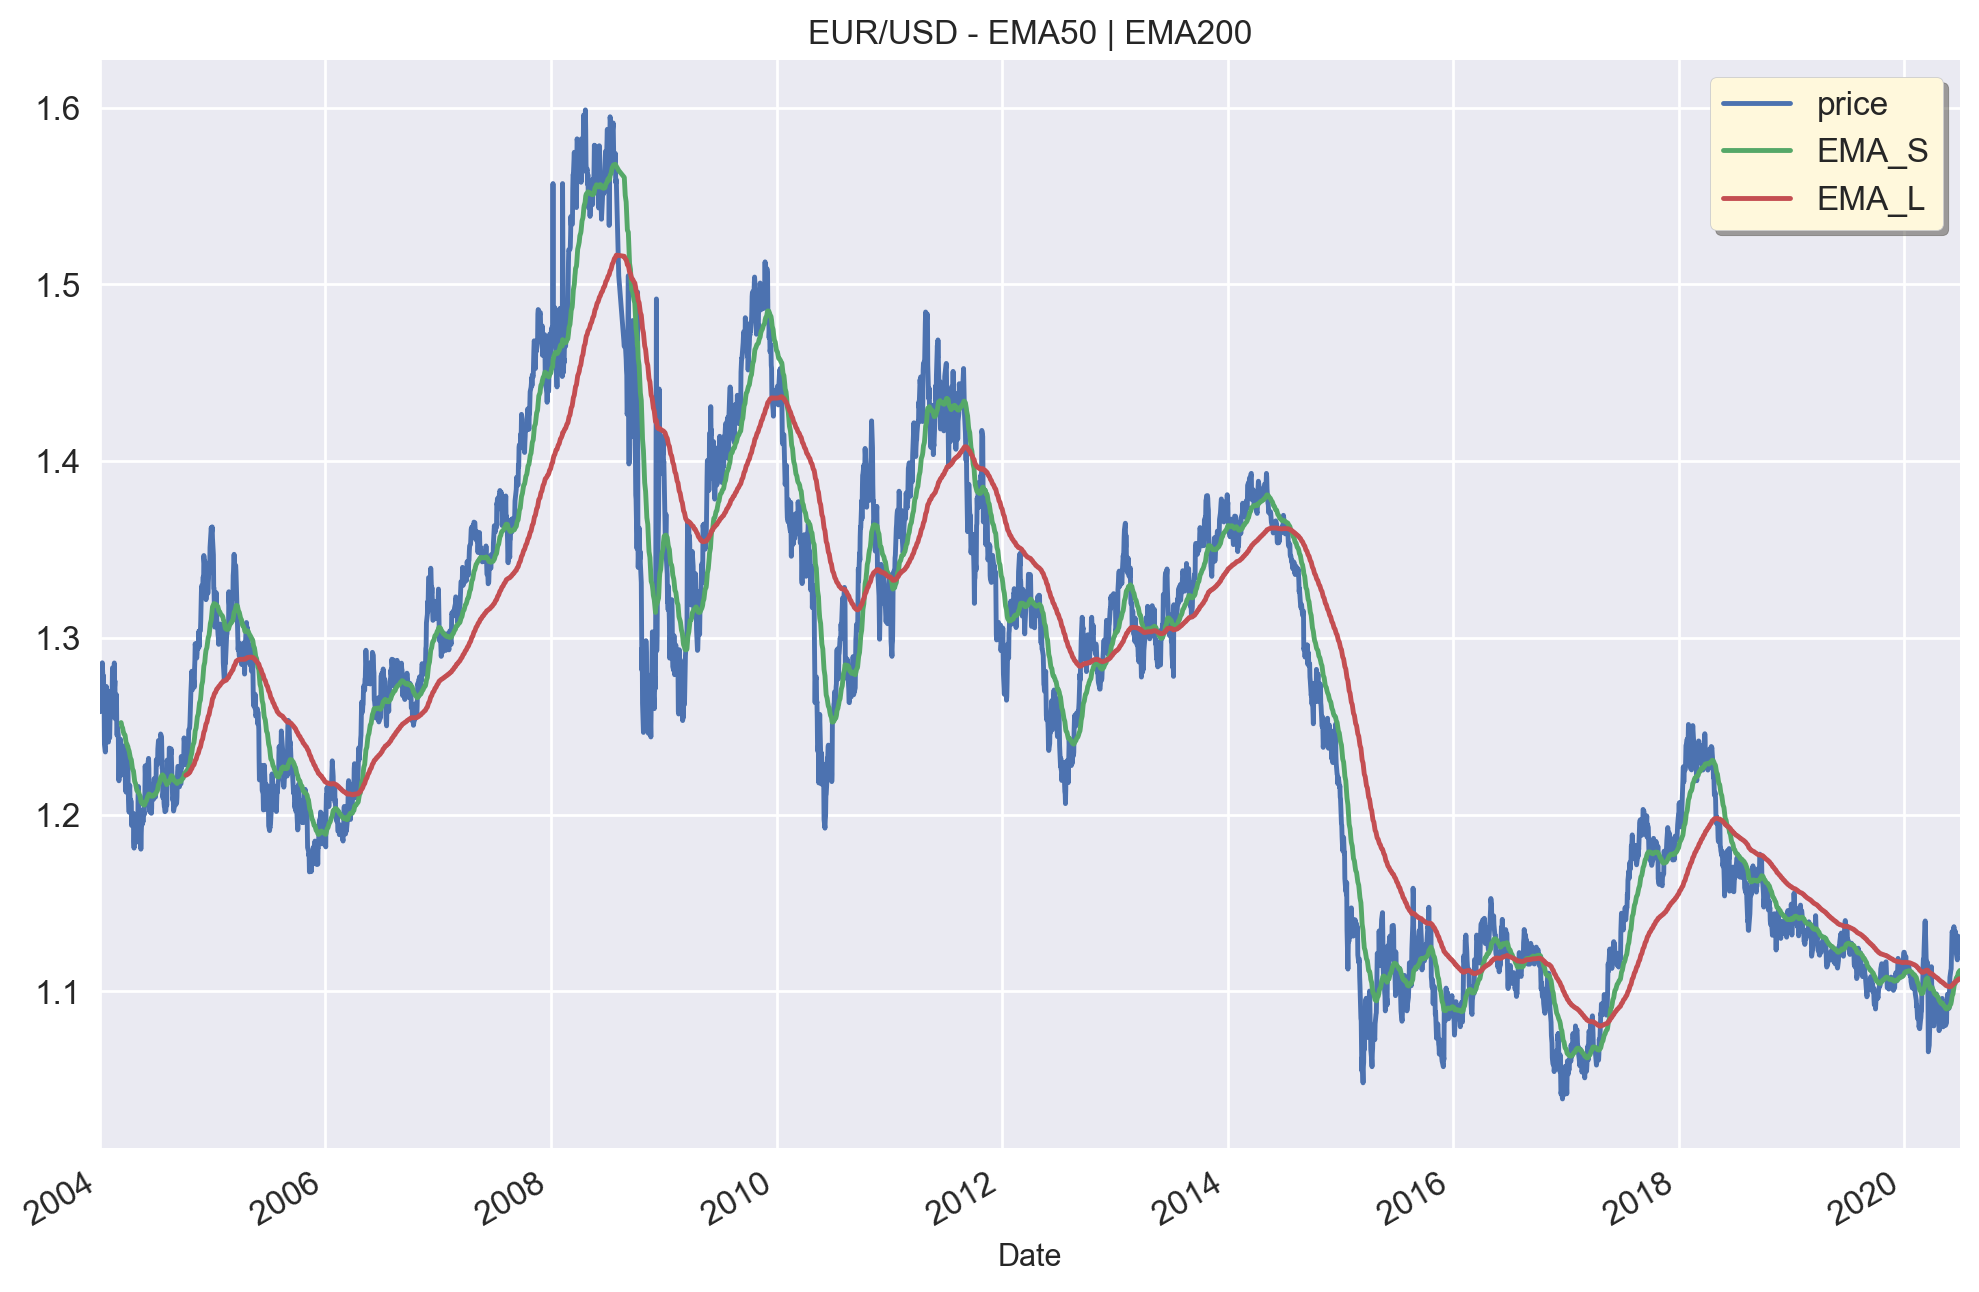

In [27]:
data.plot(figsize = (12, 8), 
          title = "EUR/USD - EMA{} | EMA{}".format(ema_s, ema_l),
          fontsize = 12)
plt.autoscale(enable=True , axis="x" , tight = True)
plt.legend(fontsize = 12 , bbox_to_anchor =(1,1) , fancybox = True , frameon = True, shadow = True , facecolor = "cornsilk")
plt.show()

In [28]:
data["position"] = np.where(data["EMA_S"] > data["EMA_L"] , +1 , -1)

In [29]:
data

,price,EMA_S,EMA_L,position
Date,,,,
2004-01-01,1.258194,NaN,NaN,-1
2004-01-02,1.258194,NaN,NaN,-1
2004-01-05,1.268698,NaN,NaN,-1
2004-01-06,1.272103,NaN,NaN,-1
2004-01-07,1.264095,NaN,NaN,-1
...,...,...,...,...
2020-06-24,1.131235,1.109674,1.106470,1
2020-06-25,1.125087,1.110279,1.106655,1
2020-06-26,1.122208,1.110746,1.106810,1


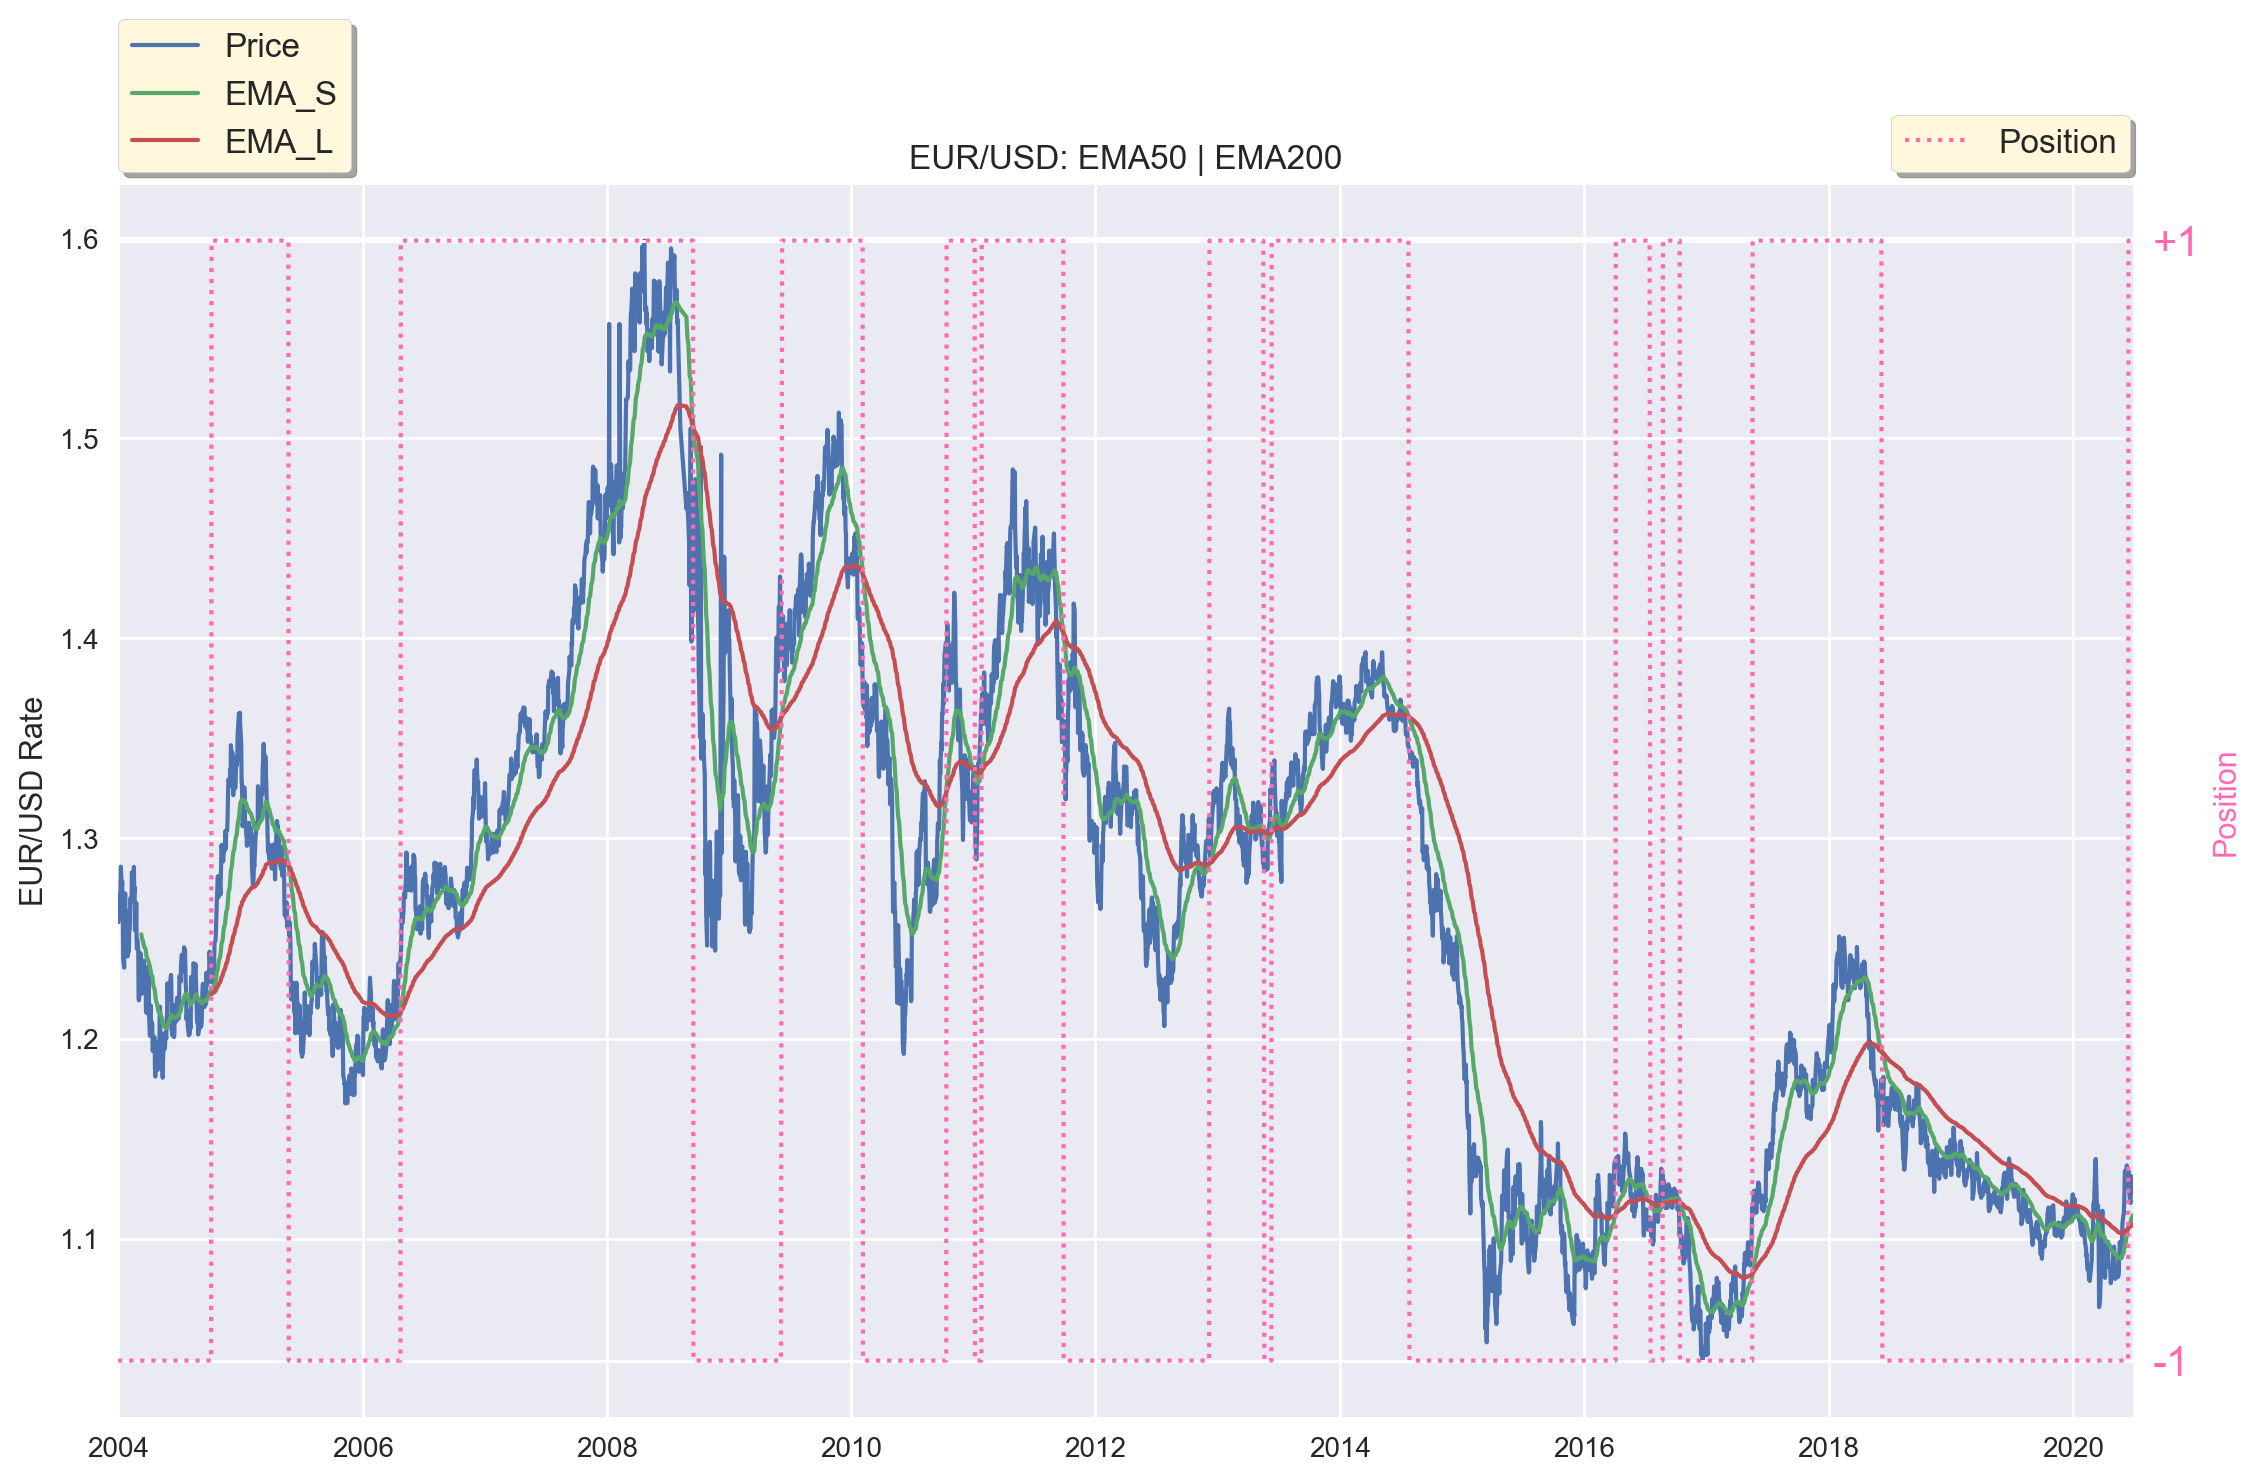

In [91]:
fig , ax = plt.subplots(figsize =(13,8))
ax.plot(data.iloc[: , 0].dropna(),
        linewidth = 1.5,
        label = "Price"
        )
ax.plot(data.iloc[: , 1].dropna(),
        linewidth = 1.5,
        label = "EMA_S"
        )
ax.plot(data.iloc[: , 2].dropna(),
        linewidth = 1.5,
        label = "EMA_L"
        )
ax.autoscale(enable=True , axis="x" , tight = True)
ax.set_title("EUR/USD: EMA{} | EMA{}".format(ema_s , ema_l))
ax.set_ylabel("EUR/USD Rate")
ax.legend( fontsize = 12 , 
           ncols = 1,
           loc = (0,1.01), 
           fancybox = True , 
           frameon = True, 
           shadow = True , 
           facecolor = "cornsilk")

ax2 = ax.twinx()
ax2.plot(data.iloc[:,3].dropna(),
         color = "hotpink",
         label = "Position",
         ls =":",
         linewidth = 1.5)
ax2.autoscale(enable=True , axis="x" , tight = True)
ax2.set_ylabel("Position" , color ="hotpink")
ax2.set_yticks(ticks = [-1 , 1] , labels = ["-1" , "+1"] , color = "hotpink" , fontsize = 15)
ax2.legend(fontsize = 12 , 
           loc = (.88 ,1.01) , 
           fancybox = True , 
           frameon = True, 
           shadow = True , 
           facecolor = "cornsilk")

plt.xlabel("Date")
plt.show()

## Vectorized Strategy Backtesting

In [92]:
data

,price,EMA_S,EMA_L,position
Date,,,,
2004-01-01,1.258194,NaN,NaN,-1
2004-01-02,1.258194,NaN,NaN,-1
2004-01-05,1.268698,NaN,NaN,-1
2004-01-06,1.272103,NaN,NaN,-1
2004-01-07,1.264095,NaN,NaN,-1
...,...,...,...,...
2020-06-24,1.131235,1.109674,1.106470,1
2020-06-25,1.125087,1.110279,1.106655,1
2020-06-26,1.122208,1.110746,1.106810,1


In [93]:
data["log_ret"] = np.log(data["price"]/data["price"].shift(1))

In [94]:
data

,price,EMA_S,EMA_L,position,log_ret
Date,,,,,
2004-01-01,1.258194,NaN,NaN,-1,NaN
2004-01-02,1.258194,NaN,NaN,-1,0.000000
2004-01-05,1.268698,NaN,NaN,-1,0.008313
2004-01-06,1.272103,NaN,NaN,-1,0.002681
2004-01-07,1.264095,NaN,NaN,-1,-0.006315
...,...,...,...,...,...
2020-06-24,1.131235,1.109674,1.106470,1,0.002892
2020-06-25,1.125087,1.110279,1.106655,1,-0.005449
2020-06-26,1.122208,1.110746,1.106810,1,-0.002562


In [95]:
data = data.dropna()

In [96]:
data

,price,EMA_S,EMA_L,position,log_ret
Date,,,,,
2004-10-06,1.228094,1.223852,1.222221,1,-0.002853
2004-10-07,1.229906,1.224089,1.222309,1,0.001475
2004-10-08,1.241003,1.224753,1.222524,1,0.008982
2004-10-11,1.238405,1.225288,1.222706,1,-0.002095
2004-10-12,1.232104,1.225556,1.222813,1,-0.005102
...,...,...,...,...,...
2020-06-24,1.131235,1.109674,1.106470,1,0.002892
2020-06-25,1.125087,1.110279,1.106655,1,-0.005449
2020-06-26,1.122208,1.110746,1.106810,1,-0.002562


In [97]:
data["strategy"] = data["position"].shift(1) * data["log_ret"]

In [98]:
data

,price,EMA_S,EMA_L,position,log_ret,strategy
Date,,,,,,
2004-10-06,1.228094,1.223852,1.222221,1,-0.002853,NaN
2004-10-07,1.229906,1.224089,1.222309,1,0.001475,0.001475
2004-10-08,1.241003,1.224753,1.222524,1,0.008982,0.008982
2004-10-11,1.238405,1.225288,1.222706,1,-0.002095,-0.002095
2004-10-12,1.232104,1.225556,1.222813,1,-0.005102,-0.005102
...,...,...,...,...,...,...
2020-06-24,1.131235,1.109674,1.106470,1,0.002892,0.002892
2020-06-25,1.125087,1.110279,1.106655,1,-0.005449,-0.005449
2020-06-26,1.122208,1.110746,1.106810,1,-0.002562,-0.002562


In [99]:
data = data.dropna()
data

,price,EMA_S,EMA_L,position,log_ret,strategy
Date,,,,,,
2004-10-07,1.229906,1.224089,1.222309,1,0.001475,0.001475
2004-10-08,1.241003,1.224753,1.222524,1,0.008982,0.008982
2004-10-11,1.238405,1.225288,1.222706,1,-0.002095,-0.002095
2004-10-12,1.232104,1.225556,1.222813,1,-0.005102,-0.005102
2004-10-13,1.234903,1.225922,1.222951,1,0.002270,0.002270
...,...,...,...,...,...,...
2020-06-24,1.131235,1.109674,1.106470,1,0.002892,0.002892
2020-06-25,1.125087,1.110279,1.106655,1,-0.005449,-0.005449
2020-06-26,1.122208,1.110746,1.106810,1,-0.002562,-0.002562


In [100]:
data["trades"] = data["position"].diff().fillna(0).abs()

In [101]:
data.trades.value_counts()

0.0    4055
2.0      20
Name: trades, dtype: int64

In [102]:
data[data["trades"] !=0]

,price,EMA_S,EMA_L,position,log_ret,strategy,trades
Date,,,,,,,
2005-05-25,1.259906,1.285905,1.286237,-1,0.002466,0.002466,2.0
2006-04-25,1.242900,1.213470,1.213251,1,0.003226,-0.003226,2.0
2008-09-16,1.413507,1.504807,1.505274,-1,-0.009430,-0.009430,2.0
2009-06-08,1.390298,1.361277,1.360992,1,-0.004948,0.004948,2.0
2010-02-05,1.368008,1.430674,1.431572,-1,-0.004731,-0.004731,2.0
2010-10-13,1.391692,1.324764,1.323442,1,0.002641,-0.002641,2.0
2011-01-06,1.315686,1.333836,1.334274,-1,-0.012405,-0.012405,2.0
2011-01-26,1.368607,1.333966,1.333864,1,0.003075,-0.003075,2.0
2011-09-28,1.358234,1.401739,1.402471,-1,0.004743,0.004743,2.0


In [103]:
spread = 1.5 * (10**-4) # 1pips = 10**(-4)
commission = 0

In [104]:
half_spread = spread/2
half_spread

7.500000000000001e-05

In [106]:
pct = half_spread / data.price.mean()
pct

5.93304228050709e-05

In [108]:
print(f"pct:{pct:.5f}")

pct:0.00006


In [109]:
ptc = 0.00007 # ptc: proportion of trading cost

In [110]:
data["strategy_net"] = data["strategy"] - data["trades"] * ptc


In [111]:
data["cum_log_ret"] = np.exp(data["log_ret"].cumsum())
data["cum_strategy"] = np.exp(data["strategy"].cumsum())
data["cum_strategy_net"] = np.exp(data["strategy_net"].cumsum())

In [112]:
data

,price,EMA_S,EMA_L,position,log_ret,strategy,trades,strategy_net,cum_log_ret,cum_strategy,cum_strategy_net
Date,,,,,,,,,,,
2004-10-07,1.229906,1.224089,1.222309,1,0.001475,0.001475,0.0,0.001475,1.001476,1.001476,1.001476
2004-10-08,1.241003,1.224753,1.222524,1,0.008982,0.008982,0.0,0.008982,1.010511,1.010511,1.010511
2004-10-11,1.238405,1.225288,1.222706,1,-0.002095,-0.002095,0.0,-0.002095,1.008396,1.008396,1.008396
2004-10-12,1.232104,1.225556,1.222813,1,-0.005102,-0.005102,0.0,-0.005102,1.003265,1.003265,1.003265
2004-10-13,1.234903,1.225922,1.222951,1,0.002270,0.002270,0.0,0.002270,1.005545,1.005545,1.005545
...,...,...,...,...,...,...,...,...,...,...,...
2020-06-24,1.131235,1.109674,1.106470,1,0.002892,0.002892,0.0,0.002892,0.921130,1.283363,1.279774
2020-06-25,1.125087,1.110279,1.106655,1,-0.005449,-0.005449,0.0,-0.005449,0.916125,1.276389,1.272820
2020-06-26,1.122208,1.110746,1.106810,1,-0.002562,-0.002562,0.0,-0.002562,0.913781,1.273123,1.269563


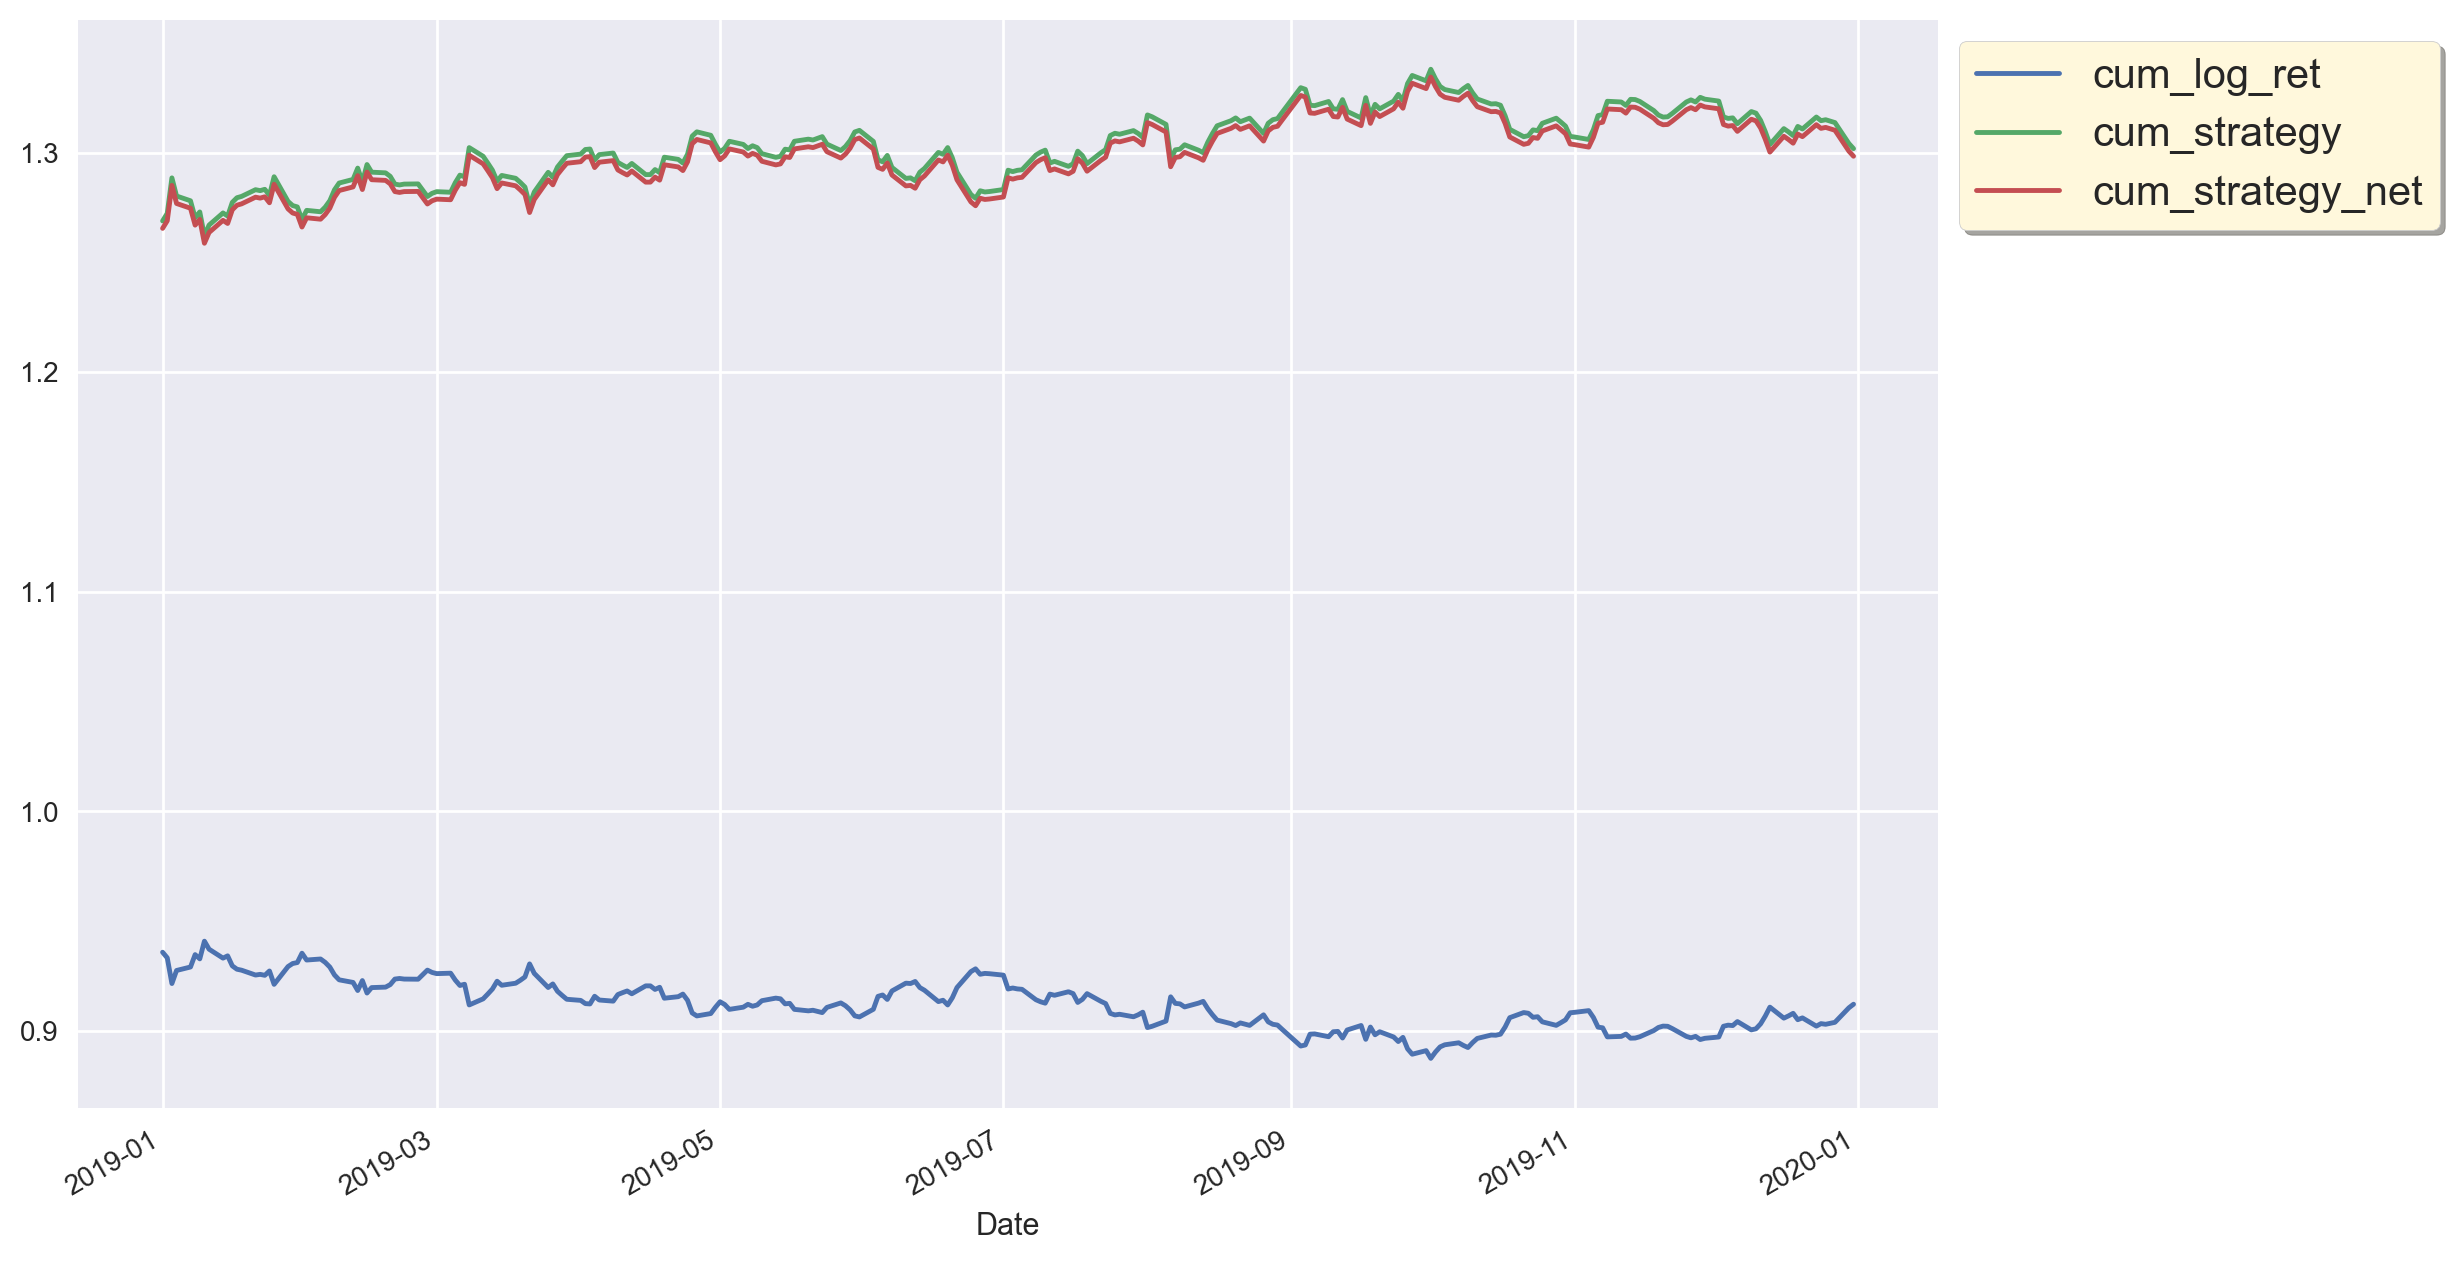

In [115]:
data.loc["2019",["cum_log_ret", "cum_strategy", "cum_strategy_net"]].plot(figsize = (12 , 8))
plt.legend(fontsize = 15, loc = "upper left", bbox_to_anchor = (1, 1), frameon = True, shadow = True, facecolor = "cornsilk", fancybox = True)
plt.show()

## Using the EMABacktester Class

In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brute
plt.style.use("seaborn-v0_8")
%config InlineBackend.figure_format = "retina"

In [117]:
from EMABacktester import EMABacktester as EMA

In [118]:
ptc = 0.00007 # ptc: proportion of trading cost

In [119]:
tester = EMA("EURUSD=X", 50, 200, "2004-01-01", "2020-06-30", ptc)

In [120]:
tester

EMABacktester(symbol = EURUSD=X, EMA_S = 50, EMA_L = 200, start = 2004-01-01, end = 2020-06-30)

In [121]:
tester.test_strategy()

(1.272405, 0.356579)

In [123]:
%config InlineBackend.figure_format = "retina"

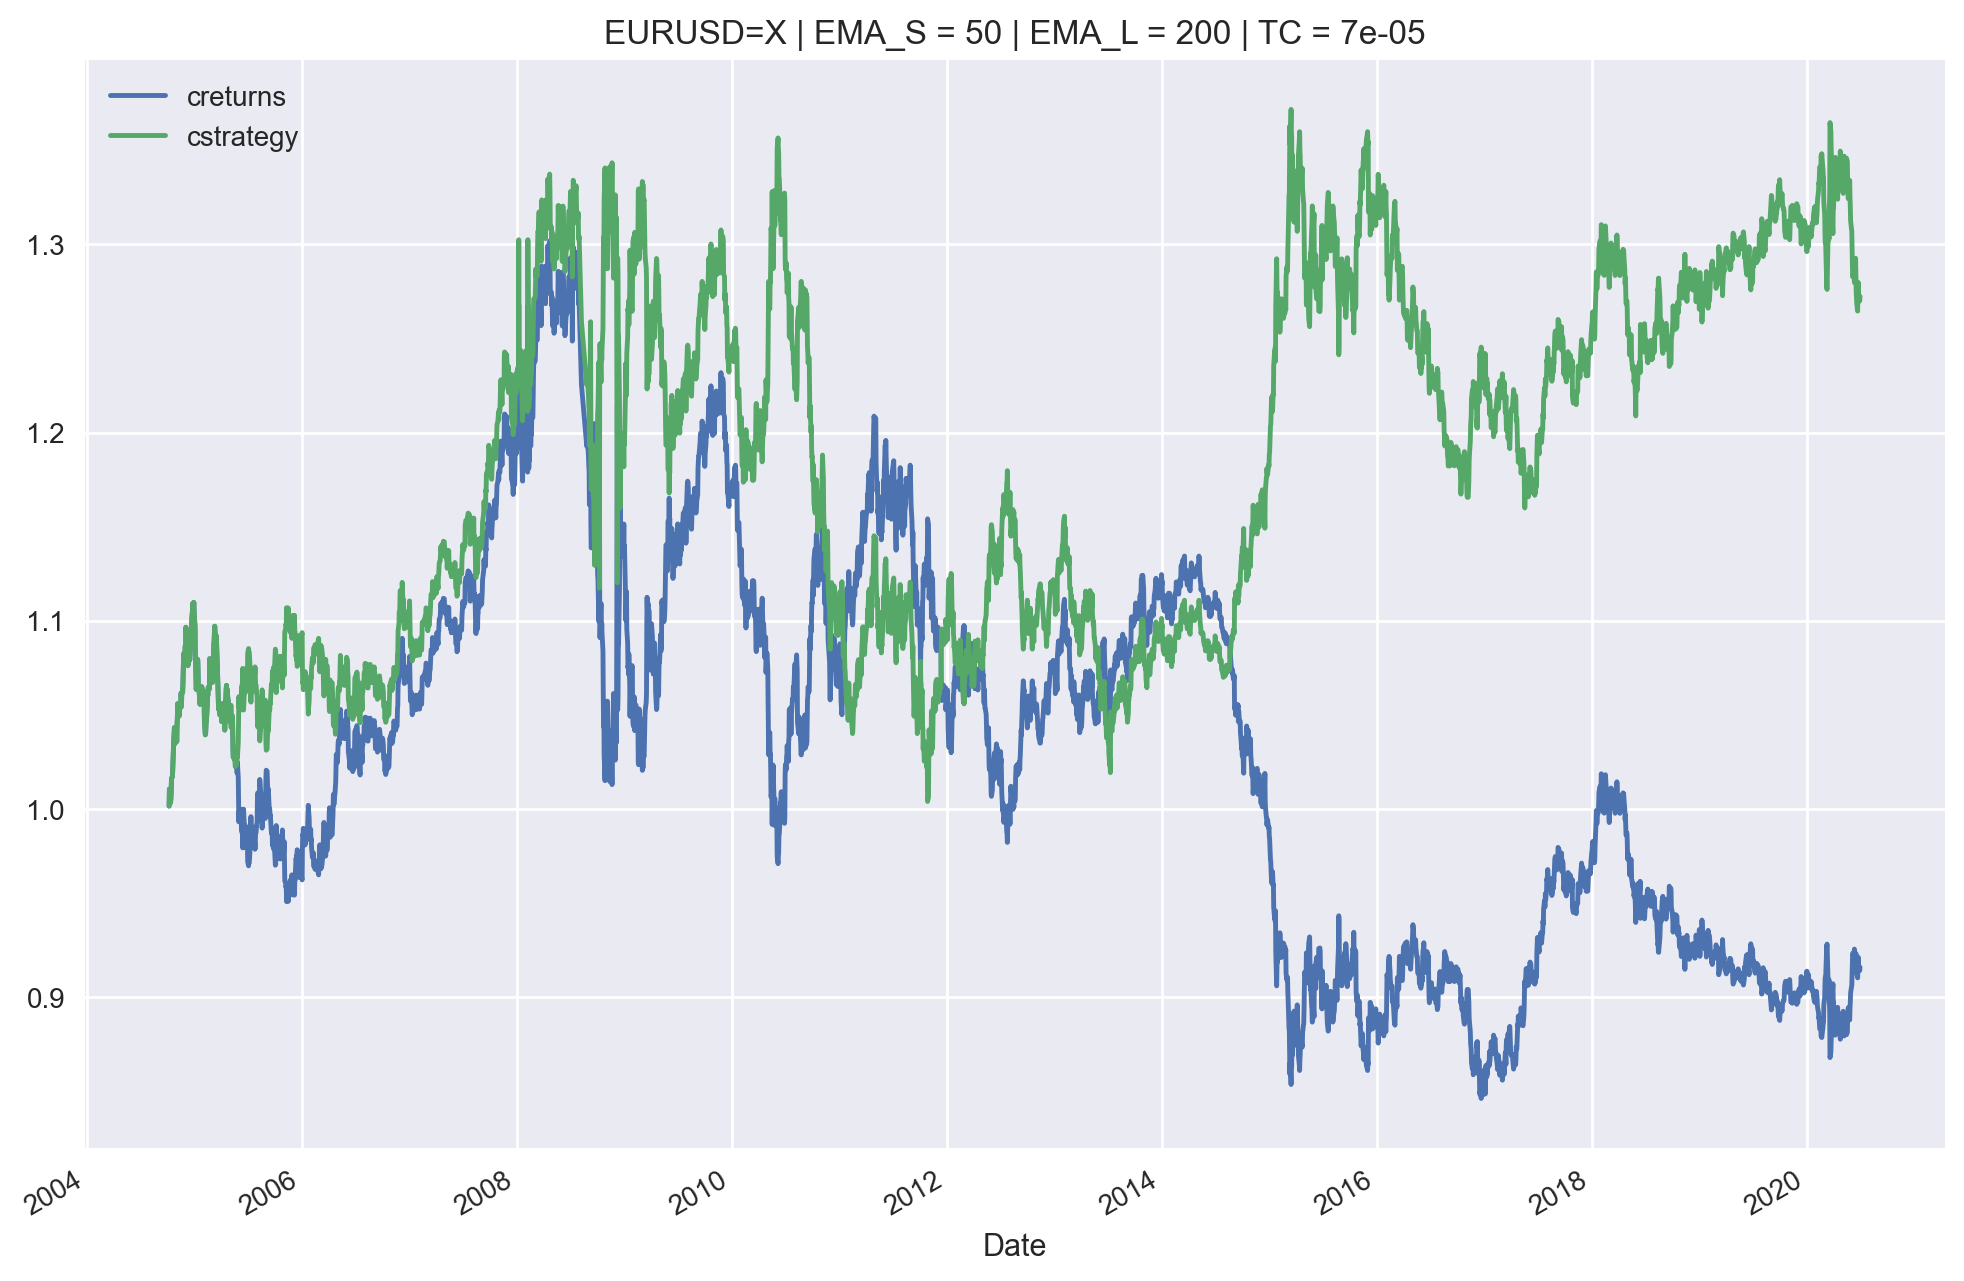

In [124]:
tester.plot_results()

In [125]:
tester.optimize_parameters((25, 75, 1), (100, 200, 1))

(array([ 36., 168.]), 1.661631)

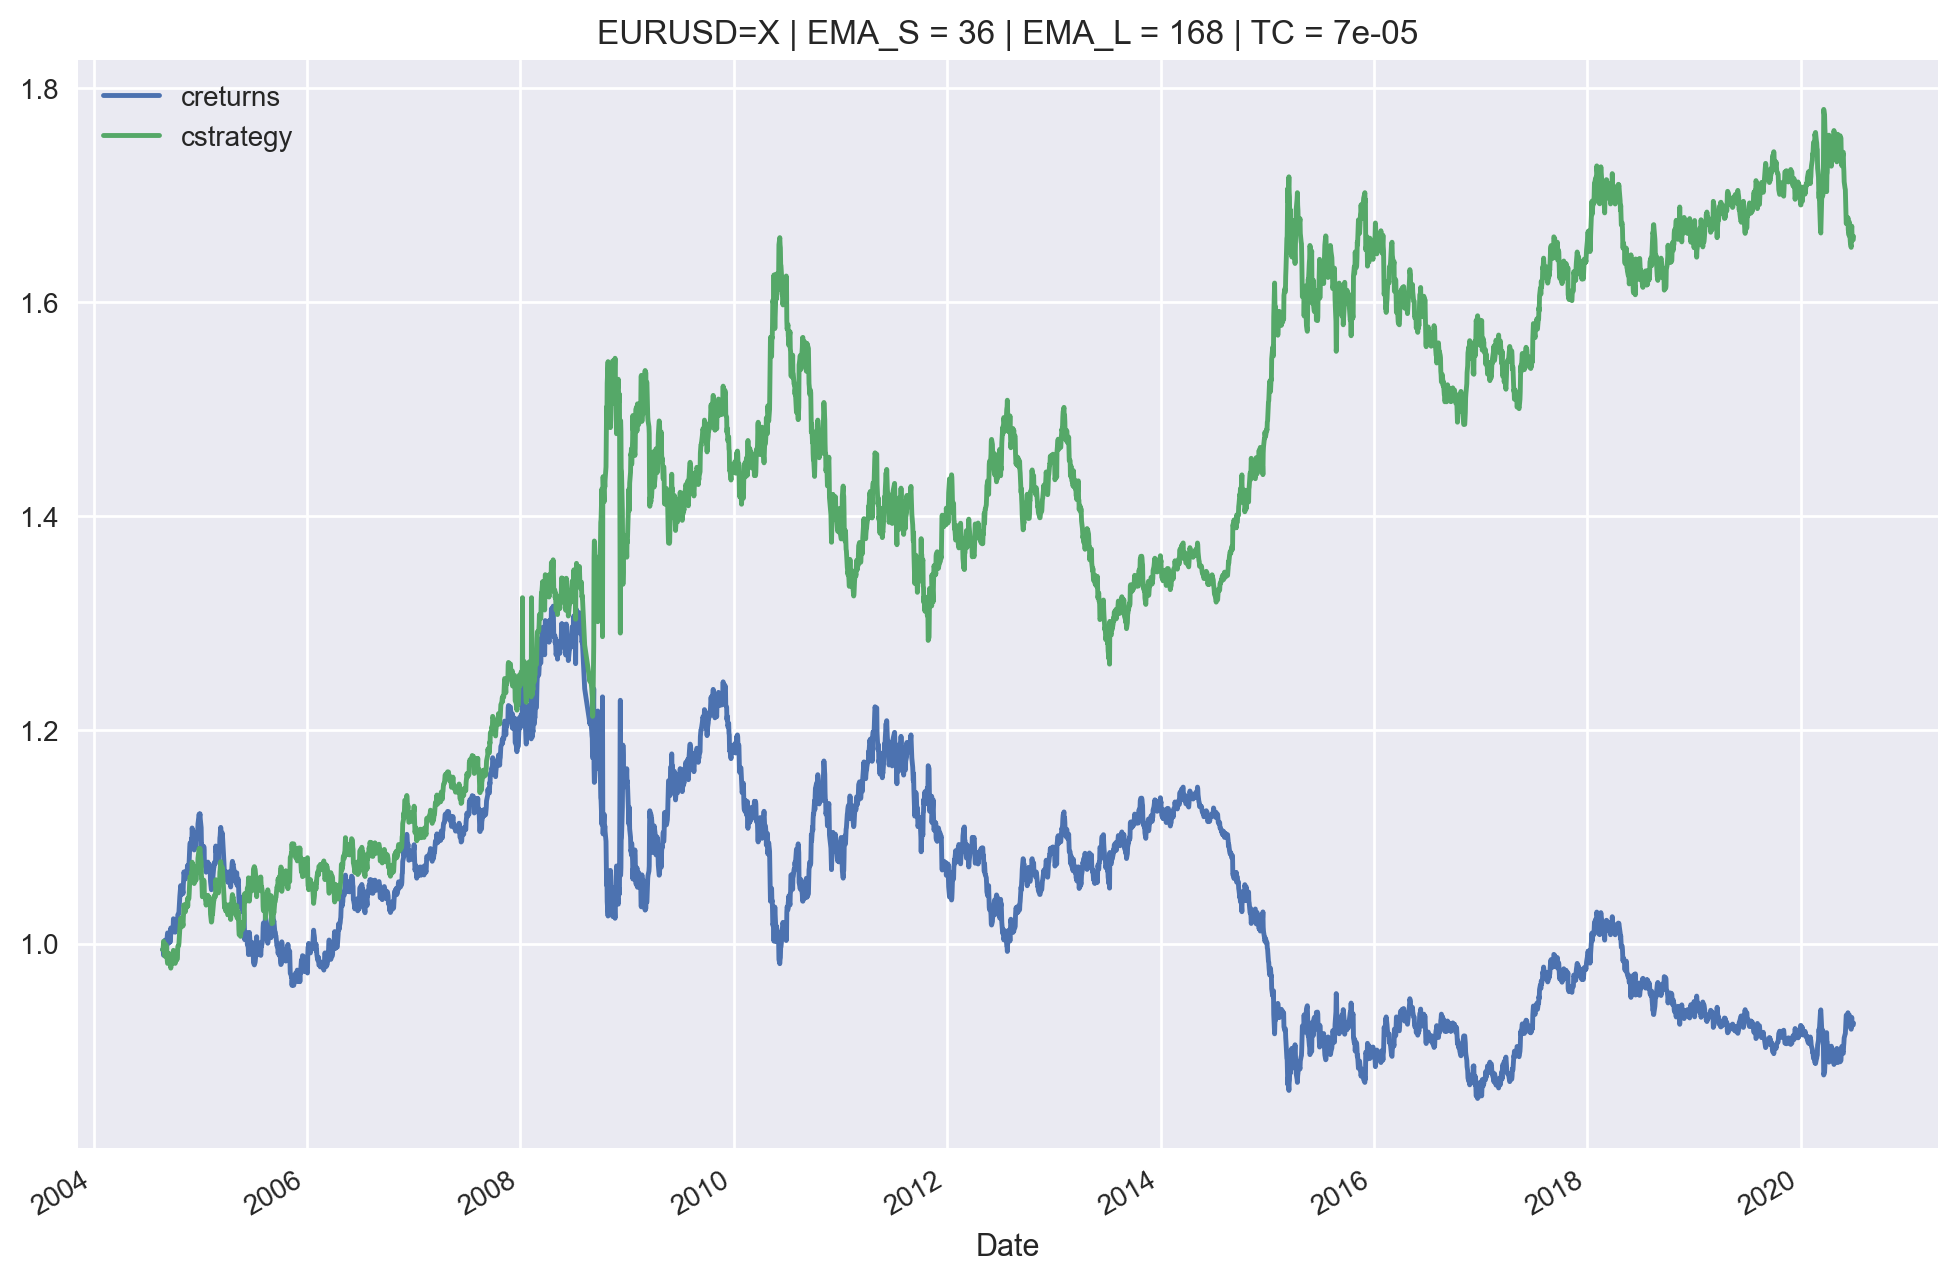

In [126]:
tester.plot_results()

__Special Case: Price/EMA Crossover__

In [127]:
tester.set_parameters(1, 50)

In [128]:
tester.test_strategy()

(0.507159, -0.412333)

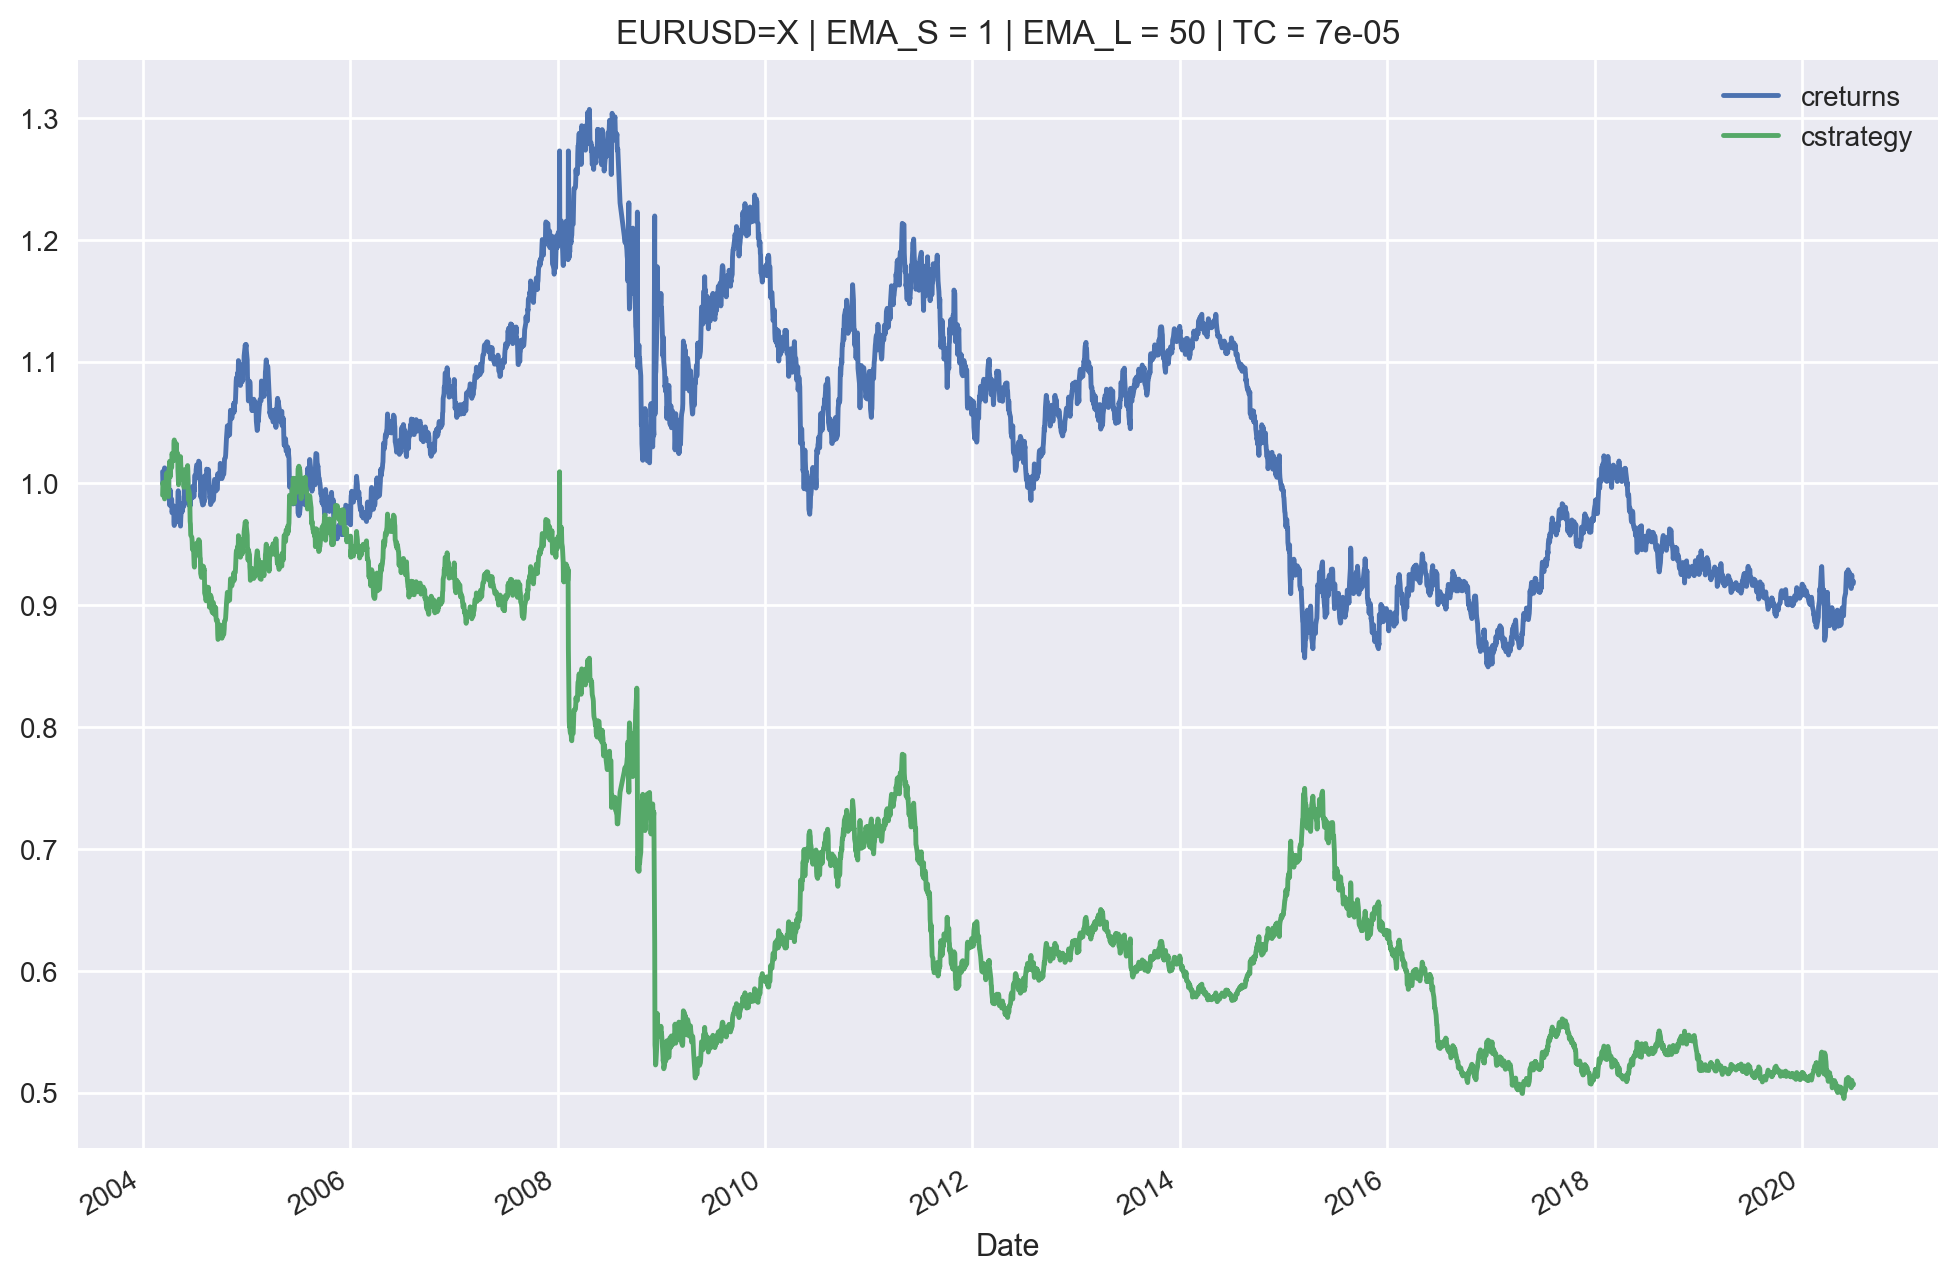

In [129]:
tester.plot_results()

In [130]:
tester.results.trades.value_counts()

0.0    3858
2.0     367
Name: trades, dtype: int64

__AUD / EUR__

In [131]:
tester = EMA("AUDEUR=X", 50, 200, "2004-01-01", "2020-06-30", 0)

In [132]:
tester.test_strategy()

(0.966382, -0.072754)

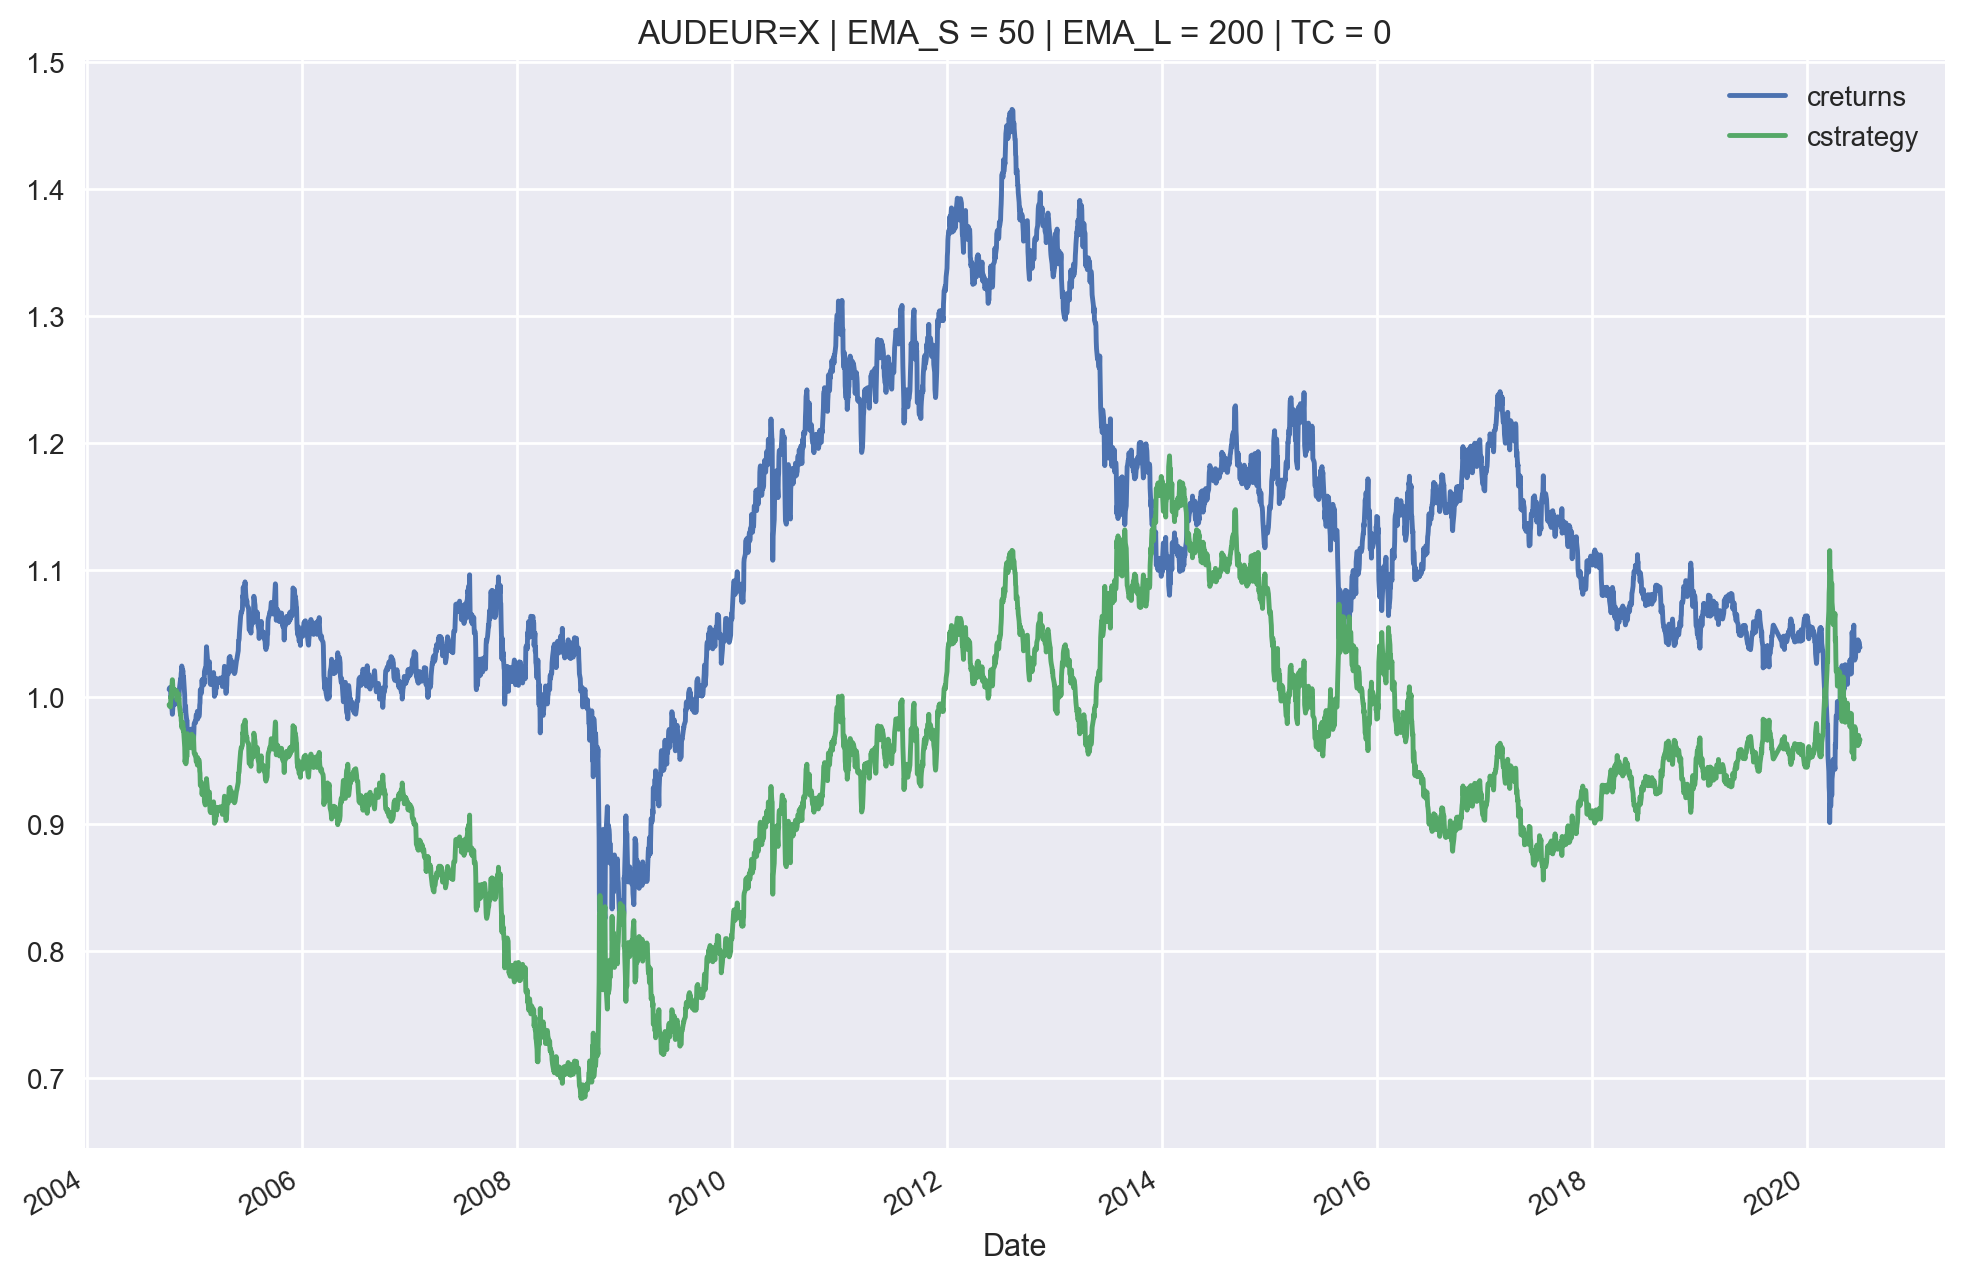

In [133]:
tester.plot_results()

In [134]:
tester.optimize_parameters((25, 75, 1), (100, 200, 1))

(array([ 71., 144.]), 1.201493)

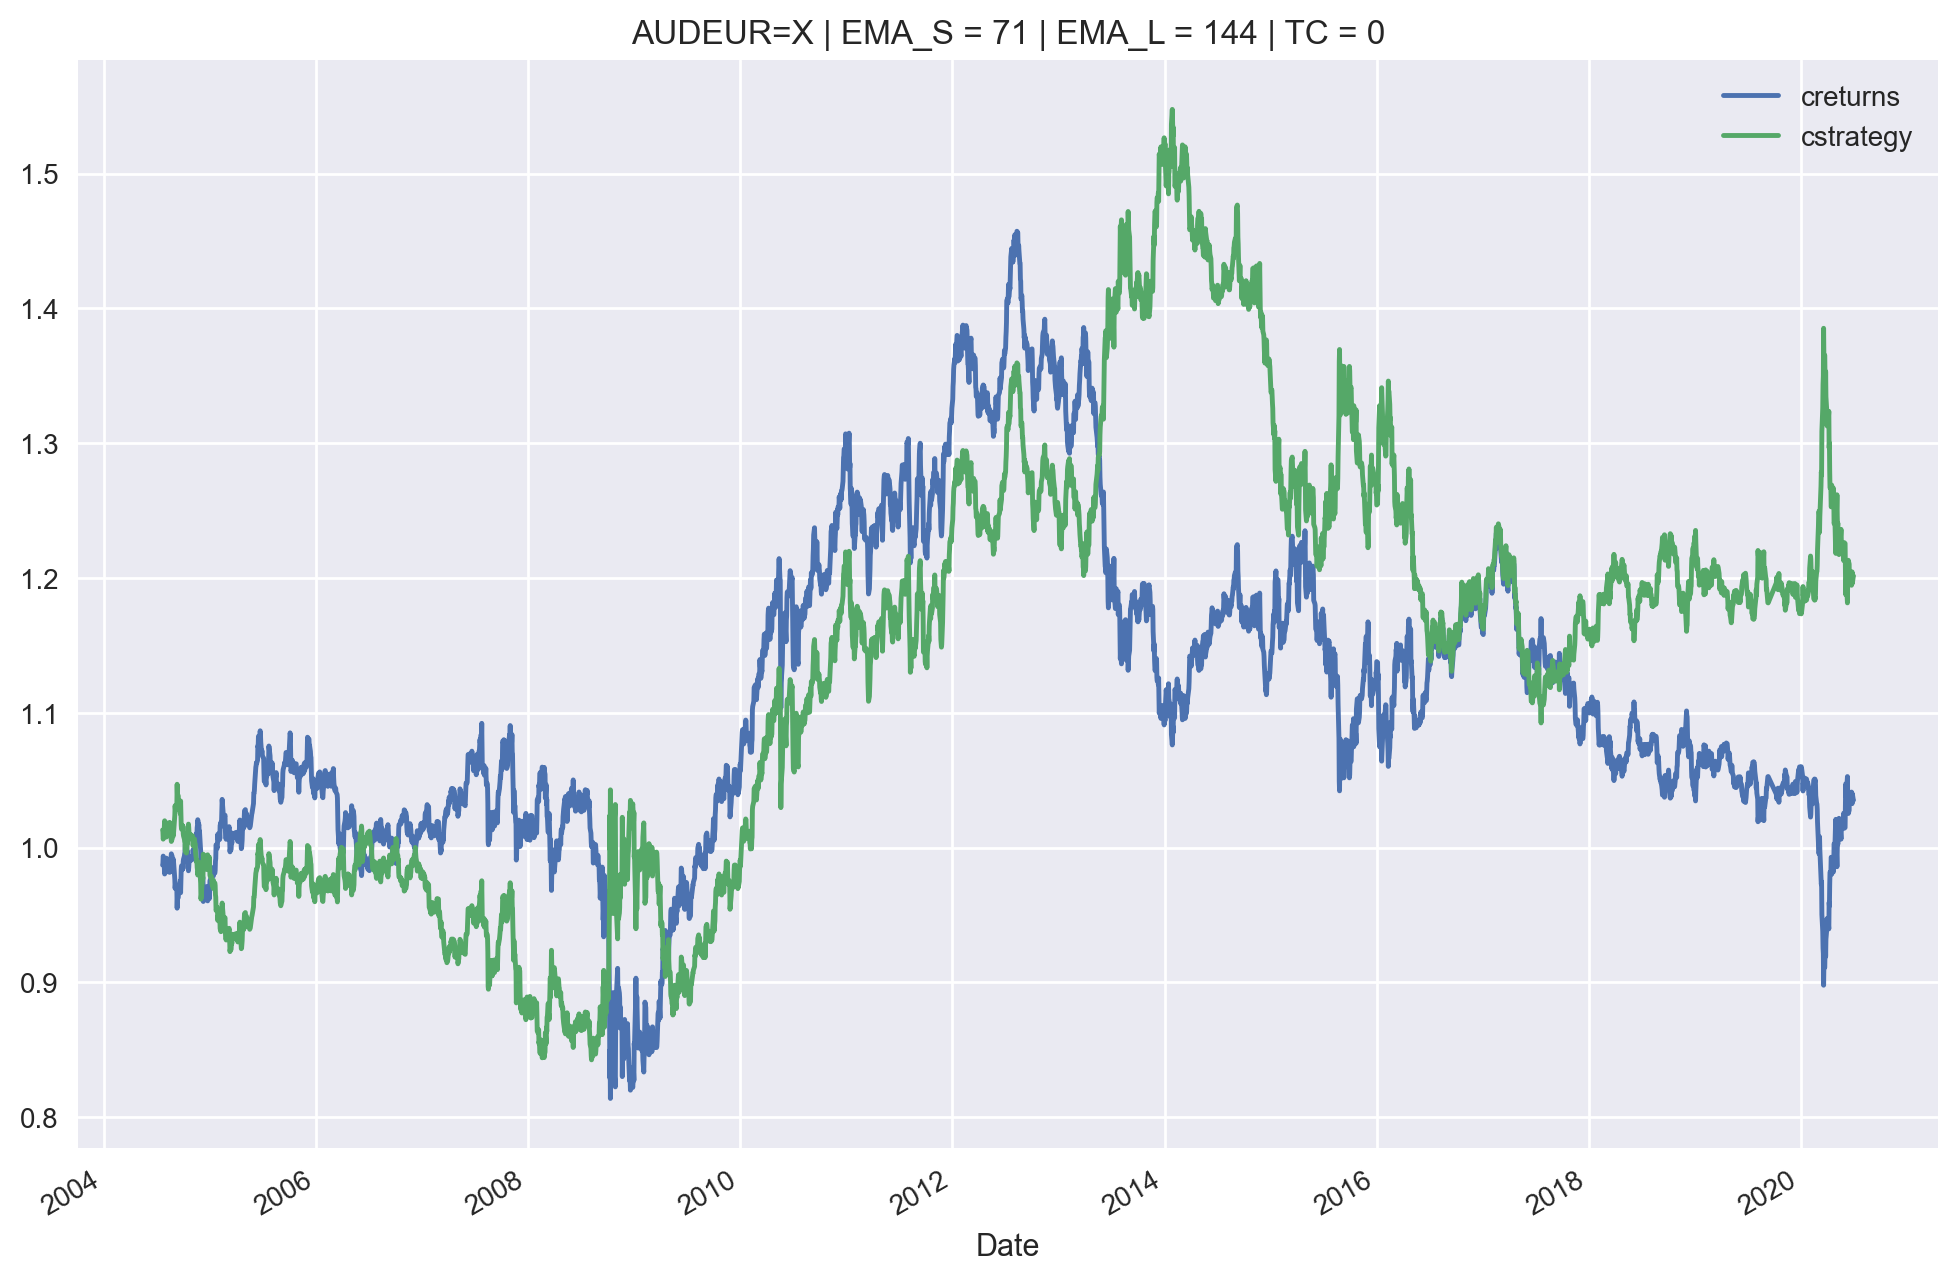

In [135]:
tester.plot_results()